# Capítulo 5 · Aprendizaje por refuerzo multiagente

**Lectura:** pp. 121–146; §§5.1–5.3. [Capítulo original](https://arxiv.org/html/2412.05265v5#Ch5).

**Idea central:** cuando otros agentes también aprenden, “hacer lo mejor” depende de sus estrategias y del concepto de solución que se adopte.

## Resumen

§5.1 amplía el modelo del entorno. Los juegos de forma normal describen decisiones conjuntas; los juegos estocásticos incorporan estados y transiciones; los POSG incluyen observaciones parciales. Las recompensas pueden ser compartidas, de suma cero o generales. En juegos extensivos importan el orden de las decisiones y los conjuntos de información: dos historias pueden ser indistinguibles para un jugador.

Desde la perspectiva de un agente, cambiar la política de otro cambia el entorno efectivo, aunque las reglas permanezcan fijas. Esta no estacionariedad complica aplicar algoritmos diseñados para un único agente. La información pública y privada también condiciona qué puede aprenderse y qué puede utilizarse al actuar.

§5.2 distingue conceptos que no deben confundirse. Una mejor respuesta es óptima frente a rivales fijos. En suma cero de dos jugadores, minimax busca robustez frente al adversario. Un equilibrio de Nash no permite mejora unilateral, pero puede ser socialmente malo o no ser único. El equilibrio correlacionado permite recomendaciones dependientes de una señal común. Pareto, bienestar y equidad expresan criterios diferentes.

La explotabilidad y NashConv miden vulnerabilidad frente a mejores respuestas. Una recompensa media de cero no basta para certificar equilibrio: una estrategia puede empatar contra un rival particular y ser muy explotable por otro. El arrepentimiento compara resultados con acciones o políticas alternativas. Los valores de Shapley estudian contribuciones individuales a resultados compartidos. Stackelberg modela compromiso y respuesta entre líder y seguidor.

§5.3 recorre estrategias de aprendizaje. Centralizar todas las decisiones es sencillo conceptualmente, pero puede ser costoso o incompatible con información local. Aprender de forma independiente es práctico, aunque puede oscilar. CTDE permite críticos con información global durante entrenamiento y políticas locales durante ejecución. VDN y QMIX descomponen valores conjuntos bajo restricciones que facilitan escoger acciones por separado.

El self-play aprovecha la simetría, pero no ofrece convergencia universal. Fictitious play responde a la estrategia media del rival; las poblaciones y PSRO amplían el conjunto de oponentes para mejorar robustez. CFR minimiza arrepentimiento contrafactual en conjuntos de información; sus garantías clásicas se refieren a políticas medias y juegos bajo supuestos concretos, como dos jugadores de suma cero y recuerdo perfecto.

El capítulo cierra con métodos regularizados como MMD, comparaciones con PPO, planificación al decidir y aplicaciones a agentes lingüísticos. Es crucial separar resultados demostrados en juegos tabulares de observaciones empíricas con aproximación neuronal.

## Ecuaciones esenciales

Un equilibrio de Nash satisface, para cada jugador $i$,

$$
J_i(\pi_i,\pi_{-i})\geq J_i(\pi'_i,\pi_{-i})
\quad\text{para cualquier }\pi'_i.
$$

En un juego matricial de suma cero con matriz de pagos $A$, el laboratorio usa

$$
\operatorname{NashConv}(p,q)=\max_i(Aq)_i-\min_j(p^\top A)_j.
$$

Es la suma de las dos mejoras unilaterales posibles. Algunas convenciones de explotabilidad dividen esta cantidad entre dos; aquí no lo hacemos.

## Experimento 5 · Piedra, papel y tijera

**Pregunta:** ¿la estrategia actual y la estrategia media se comportan igual durante el aprendizaje?

Dos jugadores usan regret matching durante 4.000 iteraciones. Mantienen el arrepentimiento acumulado de cada acción y asignan probabilidad proporcional a su parte positiva. Se inicializan con distribuciones aleatorias para evitar el caso trivial de empezar exactamente en el equilibrio uniforme.

Calculamos los pagos esperados de todas las acciones frente al rival. Es un experimento de información completa, no un aprendizaje basado únicamente en el premio de una acción muestreada.

~~~bash
uv run python -m experimentos.ejecutar --capitulo 5
~~~

**Métricas:** NashConv de las políticas actuales y de las medias temporales; distribución media sobre las tres acciones. Las 20 réplicas corresponden a inicializaciones diferentes.

**Resultado observado:** la política media se aproxima a $(1/3,1/3,1/3)$ y su NashConv final ronda 0.031. La de las políticas actuales ronda 1.67: no se estabilizan del mismo modo. La media entre semillas que se dibuja en una curva no sustituye a la media temporal que usa el algoritmo.

**Modificación:** enfrenta la política aprendida a un rival que siempre juega piedra. Una mejor respuesta explotará su debilidad, mientras la estrategia de equilibrio prioriza robustez ante cualquier rival.

**Límite:** implementamos regret matching en un juego matricial, un caso elemental relacionado con CFR. No implementamos CFR para póquer ni demostramos resultados para cooperación o suma general.



## Para el grupo

1. ¿Por qué “nadie quiere desviarse” no equivale a “todos están satisfechos”?
2. ¿Qué información puede usar un crítico centralizado que no debería recibir el actor al ejecutar?
3. ¿Qué conclusiones cambiarían si solo observáramos pagos de acciones elegidas?

**Conexión:** no estacionariedad, preferencias y self-play reaparecen al entrenar sistemas con LLM.


## Preparar la ejecución

Ejecuta todas las celdas en orden. El módulo contiene la implementación completa; la siguiente celda muestra su código. Cambia SEMILLA y REPLICAS para repetir. Los resultados del cuaderno se guardan en una carpeta separada.

In [1]:
from pathlib import Path
import sys
import json
import inspect
import subprocess
import importlib
from IPython.display import display, Image, Code

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next(p for p in candidates if (p / "experimentos" / "ejecutar.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
CAPITULO = 5
SEMILLA = 2026
REPLICAS = 20
SALIDA = ROOT / "resultados" / "cuadernos"
modulo = importlib.import_module(f"experimentos.cap{CAPITULO:02d}")
display(Code(inspect.getsource(modulo), language="python"))

"""Cap. 5: regret matching en piedra, papel y tijera; política actual y media."""
import numpy as np
import matplotlib.pyplot as plt
from .comun import guardar, curva, filas_finales, resumen_muestra

A = np.array([[0., -1., 1.], [1., 0., -1.], [-1., 1., 0.]])

def estrategia(regrets):
    pos = np.maximum(regrets, 0)
    return pos/pos.sum() if pos.sum() > 0 else np.ones(3)/3

def nashconv(p, q):
    # Suma de incentivos a desviarse; no dividimos por 2.
    return float(np.max(A@q)-np.min(p@A))

def entrenar(seed, pasos=4000):
    rng = np.random.default_rng(seed)
    regrets1, regrets2 = np.zeros(3), np.zeros(3)
    p, q = rng.dirichlet(np.ones(3)), rng.dirichlet(np.ones(3))
    sum_p, sum_q = np.zeros(3), np.zeros(3)
    actual, media = [], []
    for t in range(1, pasos+1):
        sum_p += p
        sum_q += q
        actual.append(nashconv(p, q))
        media.append(nashconv(sum_p/t, sum_q/t))
        u1, u2 = A@q, -A.T@p
        # Actualizaciones simultáneas a partir de las políticas previas.
        regrets1 += u1 - p@u1
        regrets2 += u2 - q@u2
        p, q = estrategia(regrets1), estrategia(regrets2)
    return np.array(actual), np.array(media), sum_p/pasos, sum_q/pasos

def ejecutar(out, seed=2026, replicas=20):
    data = [entrenar(seed+k) for k in range(replicas)]
    actual, media = np.array([d[0] for d in data]), np.array([d[1] for d in data])
    p = np.array([d[2] for d in data])
    q = np.array([d[3] for d in data])
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    x = np.arange(1, actual.shape[1]+1)
    curva(ax[0], x, actual, "Políticas actuales")
    curva(ax[0], x, media, "Políticas medias")
    ax[0].set(xlabel="Iteración", ylabel="NashConv (suma de mejoras unilaterales)", title="No confundir última política con media")
    ax[0].legend()
    ax[1].bar(np.arange(3)-.18, p.mean(axis=0), width=.36, label="Jugador 1")
    ax[1].bar(np.arange(3)+.18, q.mean(axis=0), width=.36, label="Jugador 2")
    ax[1].axhline(1/3, ls="--", color="black", label="Equilibrio")
    ax[1].set(xticks=np.arange(3), xticklabels=["Piedra", "Papel", "Tijera"],
              ylabel="Probabilidad media", ylim=(0, .5))
    ax[1].legend()
    metrics = {"iteraciones": 4000, "nashconv_actual_final": resumen_muestra(actual[:, -1]),
               "nashconv_media_final": resumen_muestra(media[:, -1]),
               "politica_media_jugador_1": p.mean(axis=0).tolist(),
               "politica_media_jugador_2": q.mean(axis=0).tolist()}
    return guardar(out, dict(actual=actual, media=media, p=p, q=q), filas_finales("NashConv media", media[:, -1]),
                   metrics, fig)

## Ejecutar y registrar

El comando utiliza el mismo Python del kernel y conserva parámetros y hashes en su manifiesto. No necesita servicios externos.

In [2]:
command = [sys.executable, "-m", "experimentos.ejecutar",
           "--capitulo", str(CAPITULO), "--semilla", str(SEMILLA),
           "--replicas", str(REPLICAS), "--salida", str(SALIDA)]
completed = subprocess.run(command, cwd=ROOT, capture_output=True, text=True, check=True)
print(completed.stdout)
carpeta = SALIDA / f"cap{CAPITULO:02d}"

Capítulo 5: completado en 1.43 s → /home/ialab/jairo_experiments/kevinMurphy/resultados/cuadernos/cap05



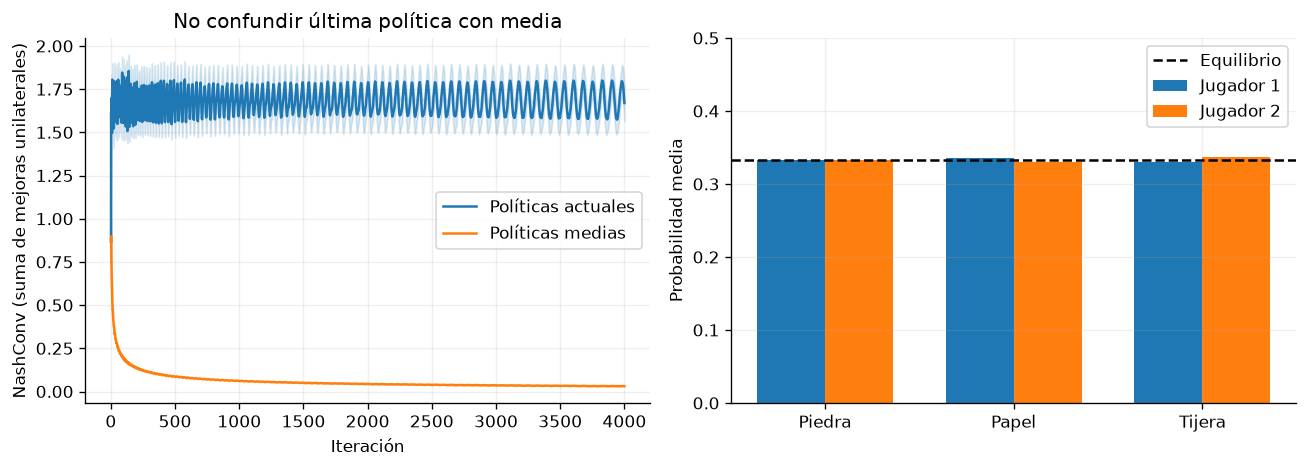

{
  "iteraciones": 4000,
  "nashconv_actual_final": {
    "media": 1.6698913880911264,
    "ic95_aprox_semianchura": 0.10490133040579429
  },
  "nashconv_media_final": {
    "media": 0.031038816525221204,
    "ic95_aprox_semianchura": 0.0005934255867106881
  },
  "politica_media_jugador_1": [
    0.3335100520612576,
    0.3359297147006584,
    0.330560233238084
  ],
  "politica_media_jugador_2": [
    0.3330859945750536,
    0.3304716765123353,
    0.3364423289126113
  ]
}


In [3]:
display(Image(filename=str(carpeta / "figura.png")))
resumen = json.loads((carpeta / "resumen.json").read_text())
print(json.dumps(resumen, indent=2, ensure_ascii=False))

## Inspeccionar los datos

Las claves describen métricas; las dimensiones suelen ser réplica × instante, excepto los arrays auxiliares. Escribe una conclusión que apoyen los datos y una limitación. Prueba la modificación propuesta en el texto; antes de ejecutarla, predice su efecto.

In [4]:
import numpy as np
with np.load(carpeta / "datos.npz") as datos:
    for nombre in datos.files:
        print(nombre, datos[nombre].shape)

actual (20, 4000)
media (20, 4000)
p (20, 3)
q (20, 3)


## Tu variante

Anota aquí: hipótesis, parámetro cambiado, métrica, resultado y limitación. Para modificar la dinámica o el algoritmo, edita el módulo mostrado o copia su función a una celda y experimenta con ella.

Fuente: [Kevin P. Murphy, Reinforcement Learning: An Overview, v5](https://arxiv.org/abs/2412.05265v5), [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Resumen adaptado y experimento propio de esta guía.